# Hipótesis HB1: satisfacción laboral y postura hacia la IA

HB1) La satisfacción laboral (`JobSat`) se relaciona con la postura hacia el uso de herramientas de IA (`AISent`).

Esta hipótesis es **bivariada** (dos variables) y usa el **Subgrupo 2**. Seguimos el flujo de la práctica 6 de la cátedra: gráfico, normalidad, homocedasticidad, elección de la prueba y lectura con alfa = 0,05.

In [1]:
%pip install pandas seaborn matplotlib scipy wget

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from wget import download
from os import path, listdir
import pandas as pd
# PARA AUMENTAR EL ANCHO PERMITIDO Y Q NO VEA DATOS CORTADOS
pd.set_option('display.max_colwidth', None)
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import shapiro, kstest

In [3]:
if not path.exists("schema.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/schema.csv")
if not path.exists("results.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv")

In [4]:
# low_memory=False evita el DtypeWarning de las columnas con tipos mezclados
raw_dataset_results = pd.read_csv("results.csv", low_memory=False)
raw_dataset_schema = pd.read_csv("schema.csv")

In [5]:
# 1. Definición de las listas de columnas para cada subgrupo
cols_g1 = ['Country', 'WorkExp', 'ConvertedCompYearly', 'CompTotal', 'Currency', 'Age', 'EdLevel', 'Employment', 'YearsCode']
cols_g2 = ['WorkExp', 'AIAcc', 'JobSat', 'AISent', 'AISelect', 'AIThreat', 'AILearnHow']

# Para el Grupo 3 extraemos dinámicamente todas las de JobSatPoints (del 1 al 15 + TEXT) para evitar hardcodearlas
cols_jobsat = [col for col in raw_dataset_results.columns if col.startswith('JobSatPoints')]
cols_g3 = ['NewRole', 'JobSat'] + cols_jobsat


cols_g4 = ['ConvertedCompYearly', 'WorkExp', 'OrgSize', 'AISelect', 'RemoteWork', 'DevType', 'Industry', 'ICorPM']

# 2. Creación de los DataFrames independientes para cada subgrupo
# Usamos .copy() para que cada compañero pueda limpiar nulos o transformar datos sin afectar el dataset original

# Subgrupo 1: Perfil Económico (Para Hipótesis A y HU1)
df_perfil_economico = raw_dataset_results[cols_g1].copy()

# Subgrupo 2: Impacto de la IA (Para Hipótesis B y HB1)
df_impacto_ia = raw_dataset_results[cols_g2].copy()

# Subgrupo 3: Cambio de Rol (Para Hipótesis C)
df_cambio_rol = raw_dataset_results[cols_g3].copy()

# Subgrupo 4: Premio Salarial (Para Hipótesis M4

df_premio_salarial = raw_dataset_results[cols_g4].copy()

Control: las columnas de cada subgrupo existen en `results` (cada lista debe salir vacía) y el esquema describe las del subgrupo 2.

In [6]:
for nombre, cols in {"g1": cols_g1, "g2": cols_g2, "g3": cols_g3, "g4": cols_g4}.items():
    print(nombre, [c for c in cols if c not in raw_dataset_results.columns])

raw_dataset_schema[raw_dataset_schema["qname"].isin(cols_g2)][["qid", "qname", "type", "question"]]

g1 []
g2 []
g3 []
g4 []


,qid,qname,type,question
54,QID14,WorkExp,TE,"How many years of professional work experience do you have? Please round to the nearest whole number, excluding any decimal points. If your answer is '0', please leave blank."
58,QID32,AILearnHow,MC,How did you learn to code for AI in the past year? Select all that apply.
67,QID26,JobSat,MC,How satisfied are you in your current professional developer role?
68,QID28,AIThreat,MC,Do you believe AI is a threat to your current job?
116,QID78,AISelect,MC,Do you currently use AI tools in your development process?
117,QID79,AISent,MC,How favorable is your stance on using AI tools as part of your development workflow?
118,QID80,AIAcc,MC,How much do you trust the accuracy of the output from AI tools as part of your development workflow?


Transformacion sobre Subgrupo 2: Satisfaccion laboral vs Postura hacia la IA

In [7]:
# 1. Chequeo del rango de JobSat (escala 0 a 10)
print("JobSat fuera de 0-10:", ((df_impacto_ia["JobSat"] < 0) | (df_impacto_ia["JobSat"] > 10)).sum())
df_impacto_ia["JobSat"].value_counts(dropna=False).sort_index()

JobSat fuera de 0-10: 0


JobSat
0.0       242
1.0       165
2.0       439
3.0       811
4.0       803
5.0      1896
6.0      3230
7.0      5590
8.0      6972
9.0      3598
10.0     2924
NaN     22521
Name: count, dtype: int64

Justificacion de limpieza para el informe:

- **Sin valores fuera de rango en `JobSat`:** es una escala de 0 a 10 y se comprobó que ningún valor la excede, así que no hizo falta corregirla. Los valores bajos (0, 1 y 2) son personas muy insatisfechas: son respuestas reales y no se eliminan.
- **Rechazo a la imputación de datos:** `JobSat` tiene cerca de la mitad de nulos y `AISent` cerca de un tercio. La pregunta de `JobSat` habla del rol profesional actual como desarrollador, por lo que posiblemente no se mostró a quienes no trabajan (es una hipótesis). Rellenarlos con promedios o medianas introduciría un sesgo artificial en una encuesta de opinión.
- **Estrategia de eliminación segura (Subsetting):** no se aplica un `.dropna()` global sobre las 172 columnas, porque las columnas de texto libre con altísima tasa de nulos eliminarían casi todas las filas válidas. Primero se aíslan las dos variables y recién entonces se eliminan las filas con nulos solo en ellas.
- **Respuesta "Unsure" de `AISent`:** significa "no sé", no es un punto de la escala entre "Indifferent" y otra categoría. Se excluye de esta hipótesis pasándola a nulo (alrededor de 760 personas. 1,5%).
- **Codificación manual de `AISent`:** es ordinal (5 niveles). El orden se define a mano con un diccionario porque pandas ordenaría alfabéticamente.

Validación de Hipótesis HB1

¿Está el nivel de satisfacción laboral relacionado con la postura frente al uso de herramientas de IA?

Partimos del Subgrupo 2 (Impacto de la IA). Las variables que usamos son:

- **Variable 1 (`JobSat`):** numérica discreta de 0 a 10, concentrada en 7 a 9 y con cola hacia los valores bajos.
- **Variable 2 (`AISent`):** categórica ordinal (MC) de 5 niveles, de "Very unfavorable" (1) a "Very favorable" (5).

Exclusión de variables no necesarias: las demás columnas del subgrupo (`WorkExp`, `AIAcc`, `AISelect`, `AIThreat`, `AILearnHow`) no intervienen en esta hipótesis.

Planteo estadístico: **H0:** la satisfacción laboral es la misma en los 5 niveles de postura. **H1:** en al menos un nivel es distinta. Nivel de significación: alfa = 0,05.

In [8]:
# 1. Codificación ordinal de AISent (1 = muy desfavorable, 5 = muy favorable). "Unsure" queda fuera del diccionario
orden_aisent = {"Very unfavorable": 1, "Unfavorable": 2, "Indifferent": 3,
                "Favorable": 4, "Very favorable": 5}
df_impacto_ia["AISent_num"] = df_impacto_ia["AISent"].map(orden_aisent)

# Control: respuestas no nulas que quedaron sin código (solo debería aparecer "Unsure")
print(df_impacto_ia[df_impacto_ia["AISent"].notna() & df_impacto_ia["AISent_num"].isna()]["AISent"].value_counts())

# 2. Nos quedamos con las dos variables y con las filas que tienen ambas respuestas
df_hipotesis_hb1 = df_impacto_ia[["JobSat", "AISent", "AISent_num"]].dropna().copy()

print(f"Total de observaciones listas para el análisis: {len(df_hipotesis_hb1)}")
df_hipotesis_hb1.head()

AISent
Unsure    759
Name: count, dtype: int64
Total de observaciones listas para el análisis: 24331


,JobSat,AISent,AISent_num
0,10.0,Indifferent,3.0
1,9.0,Indifferent,3.0
2,8.0,Favorable,4.0
3,6.0,Favorable,4.0
4,7.0,Favorable,4.0


Análisis de las variables

Antes de aplicar las pruebas miramos cómo se distribuye cada variable. `AISent` es una variable cualitativa ordinal. `JobSat` toma solo 11 valores enteros y es asimétrica hacia la izquierda.

Personas por nivel de AISent:
AISent_num
1.0    2225
2.0    2638
3.0    4311
4.0    9334
5.0    5823
Name: count, dtype: int64
Asimetría (skew) de JobSat: -1.01


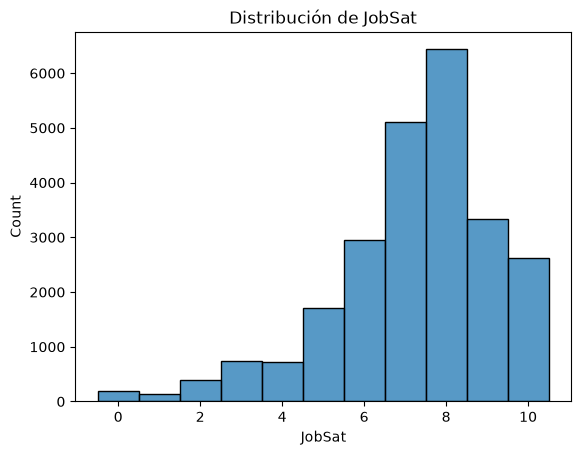

In [9]:
print("Personas por nivel de AISent:")
print(df_hipotesis_hb1["AISent_num"].value_counts().sort_index())

print("Asimetría (skew) de JobSat:", round(df_hipotesis_hb1["JobSat"].skew(), 2))

sns.histplot(df_hipotesis_hb1["JobSat"], bins=11, discrete=True)
plt.title("Distribución de JobSat")
plt.show()

Paso 1: Exploración visual

Graficamos la satisfacción de cada nivel de postura con un boxplot. Como `JobSat` es discreta, la mediana y el cuartil superior pueden coincidir y el boxplot se ve "plano" en algunos grupo. Los puntos sueltos en 0, 1 y 2 son personas muy insatisfechas, no se eliminan.

Media de JobSat por nivel de AISent:
AISent_num
1.0    6.908315
2.0    7.076573
3.0    7.118302
4.0    7.231091
5.0    7.447020
Name: JobSat, dtype: float64
Mediana de JobSat por nivel de AISent:
AISent_num
1.0    7.0
2.0    7.0
3.0    7.0
4.0    8.0
5.0    8.0
Name: JobSat, dtype: float64


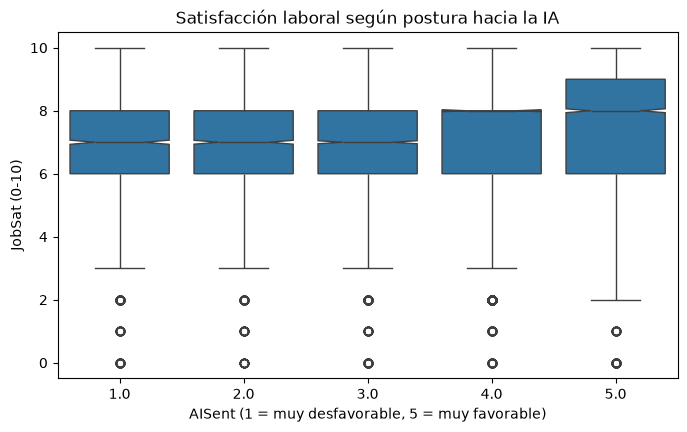

In [10]:
print("Media de JobSat por nivel de AISent:")
print(df_hipotesis_hb1.groupby("AISent_num")["JobSat"].mean())
print("Mediana de JobSat por nivel de AISent:")
print(df_hipotesis_hb1.groupby("AISent_num")["JobSat"].median())

plt.figure(figsize=(8, 4.5))
sns.boxplot(x="AISent_num", y="JobSat", data=df_hipotesis_hb1, notch=True)
plt.xlabel("AISent (1 = muy desfavorable, 5 = muy favorable)")
plt.ylabel("JobSat (0-10)")
plt.title("Satisfacción laboral según postura hacia la IA")
plt.show()

Paso 2: Normalidad

Hay que ver si `JobSat` es normal **dentro de cada grupo**. Usamos Shapiro-Wilk, Kolmogorov-Smirnov (estandarizando antes los datos) y QQ plot. La H0 de normalidad dice que los datos siguen una distribución normal: si p < 0,05 se rechaza. Con grupos de más de 5.000 datos `scipy` avisa que el p-valor de Shapiro es aproximado, es esperable.

In [11]:
grupos_hb1 = [g["JobSat"] for _, g in df_hipotesis_hb1.groupby("AISent_num")]

for i, g in enumerate(grupos_hb1, start=1):
    stat, p = shapiro(g)
    print(f"AISent = {i}: Shapiro-Wilk Estadístico={stat:.3f}, p-valor={p:.3g}")

for i, g in enumerate(grupos_hb1, start=1):
    stat, p = kstest((g - g.mean()) / g.std(), 'norm')
    print(f"AISent = {i}: Kolmogorov-Smirnov Estadístico={stat:.3f}, p-valor={p:.3g}")

AISent = 1: Shapiro-Wilk Estadístico=0.909, p-valor=1.52e-34
AISent = 2: Shapiro-Wilk Estadístico=0.918, p-valor=1.09e-35
AISent = 3: Shapiro-Wilk Estadístico=0.915, p-valor=5.27e-44
AISent = 4: Shapiro-Wilk Estadístico=0.915, p-valor=6.52e-58
AISent = 5: Shapiro-Wilk Estadístico=0.907, p-valor=9.8e-51
AISent = 1: Kolmogorov-Smirnov Estadístico=0.187, p-valor=2.49e-68
AISent = 2: Kolmogorov-Smirnov Estadístico=0.184, p-valor=2.9e-78
AISent = 3: Kolmogorov-Smirnov Estadístico=0.174, p-valor=6.5e-115
AISent = 4: Kolmogorov-Smirnov Estadístico=0.179, p-valor=1.48e-263
AISent = 5: Kolmogorov-Smirnov Estadístico=0.168, p-valor=1.43e-144


C:\Users\nahu_\AppData\Local\Programs\Python\Python314\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 9334.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\nahu_\AppData\Local\Programs\Python\Python314\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5823.
  res = hypotest_fun_out(*samples, **kwds)


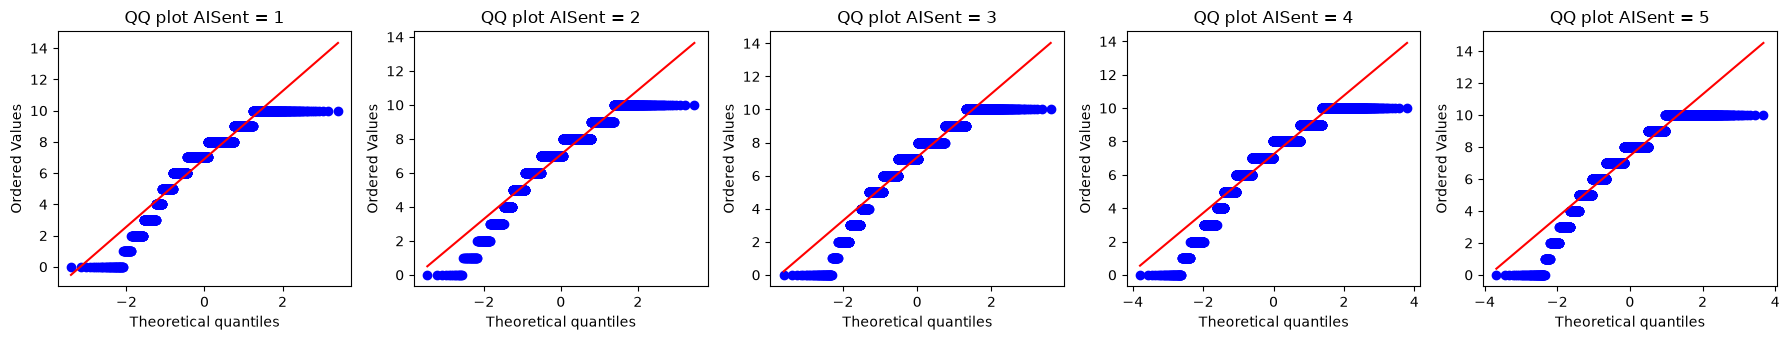

In [12]:
fig, ejes = plt.subplots(1, 5, figsize=(18, 3.5))
for i, g in enumerate(grupos_hb1):
    stats.probplot(g, dist="norm", plot=ejes[i])
    ejes[i].set_title(f"QQ plot AISent = {i + 1}")
plt.tight_layout()
plt.show()

Si los tests rechazan normalidad y el QQ plot se curva, **no se puede usar ANOVA** y corresponde una prueba no paramétrica.

Paso 3: Homocedasticidad (Levene)

H0: las varianzas de los 5 grupos son **iguales**. Si p < 0,05 se rechaza y las varianzas son distintas.

In [13]:
stat, p = stats.levene(*grupos_hb1)
print(f"Test de Levene para JobSat: Estadístico={stat:.3f}, p-valor={p:.3g}")

alpha = 0.05
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("Las varianzas de JobSat son iguales entre los grupos de AISent.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Las varianzas de JobSat son diferentes entre los grupos de AISent.")

Test de Levene para JobSat: Estadístico=22.578, p-valor=1.23e-18
Se rechaza la hipótesis nula.
Las varianzas de JobSat son diferentes entre los grupos de AISent.


Paso 4: Prueba de hipótesis (Kruskal-Wallis)

Hay **5 grupos independientes** y `JobSat` no es normal. Por eso usamos **Kruskal-Wallis**, la alternativa no paramétrica al ANOVA para comparar más de dos grupos. Solo dice **si hay diferencia** en algún grupo, no entre cuáles ni en qué sentido.

In [14]:
stat_kw, p_kw = stats.kruskal(*grupos_hb1)
print(f"Test de Kruskal-Wallis para JobSat: Estadístico={stat_kw:.3f}, p-valor={p_kw:.3g}")

alpha = 0.05
if p_kw > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en JobSat entre los niveles de AISent.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en JobSat entre los niveles de AISent.")

Test de Kruskal-Wallis para JobSat: Estadístico=156.770, p-valor=7.2e-33
Se rechaza la hipótesis nula.
Existe una diferencia significativa en JobSat entre los niveles de AISent.


Paso 5: Sentido de la asociación

Kruskal-Wallis indica que hay diferencia, pero no en qué sentido. Para eso calculamos la correlación de Spearman entre JobSat y AISent_num. Esta correlación trabaja con rangos (el orden de los valores), por lo que sirve para una variable ordinal y no exige normalidad. positiva significa que a una postura más favorable hacia la IA le corresponde más satisfacción; negativa, menos satisfacción; cercana a 0, que no hay asociación.

In [15]:
tabla_corr = df_hipotesis_hb1[["JobSat", "AISent_num"]].corr(method="spearman")
rho = tabla_corr.loc["JobSat", "AISent_num"]
print(tabla_corr)
print(f"\nCorrelación de Spearman = {rho:.3f}")

              JobSat  AISent_num
JobSat      1.000000    0.075976
AISent_num  0.075976    1.000000

Correlación de Spearman = 0.076


Con alfa = 0,05 se rechaza H0.
La satisfacción laboral difiere de forma  significativa entre los niveles de postura hacia la IA (H = 156,77; p = 7,2e-33). 
La correlación de Spearman es positiva (rho = 0,076)
A una postura más favorable hacia la IA le corresponde una satisfacción laboral levemente mayor.